# Radii of 15-frame windows

Each point is one non-overlapping 15-frame window from `annotated_config.csv`. The radii are the continuous fit inside r_r 10–80, r_o 40–250, r_a 80–500. A small jitter is added only in the figure so overlapping windows stay visible.

Rebuild the CSV first if its rows are still full annotation intervals:

`python scripts/tune_trajectories.py --extract`

In [12]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(".")
WINDOW = 15

frame = pd.read_csv(ROOT / "annotated_config.csv", dtype={"dataset": str})
span = frame["end_frame"] - frame["start_frame"]
if not (span == WINDOW).all():
    raise RuntimeError(
        "annotated_config.csv is not 15-frame windows. "
        "Run: python scripts/tune_trajectories.py --extract"
    )

meta = json.loads((ROOT / "annotations" / "datasets.json").read_text())
frame["school_size"] = frame["dataset"].str.zfill(4).map(lambda key: meta[key]["fish_group"])

BEHAVIOR_ORDER = ["traveling", "milling", "shoaling", "expansion", "compaction"]
BEHAVIOR_COLORS = {
    "traveling": "#4c78a8",
    "milling": "#f58518",
    "shoaling": "#54a24b",
    "expansion": "#e45756",
    "compaction": "#b279a2",
}
SIZE_ORDER = ["10_fish", "30_fish", "70_fish", "150_fish"]
SIZE_COLORS = {
    "10_fish": "#1b9e77",
    "30_fish": "#d95f02",
    "70_fish": "#7570b3",
    "150_fish": "#e7298a",
}

rng = np.random.default_rng(0)
jittered = frame[["r_r", "r_o", "r_a"]].to_numpy(dtype=float) + rng.normal(0.0, 2.0, size=(len(frame), 3))
print(f"{len(frame)} windows")

PROJECTIONS = (("r_r", "r_o", 0, 1), ("r_o", "r_a", 1, 2), ("r_r", "r_a", 0, 2))


def scatter_radii(order, column, colors):
    """One 3D scatter and the three pairwise projections."""
    fig = plt.figure(figsize=(12, 10))
    ax3 = fig.add_subplot(2, 2, 1, projection="3d")
    axes = [fig.add_subplot(2, 2, i) for i in (2, 3, 4)]
    labels = frame[column].to_numpy()
    for name in order:
        mask = labels == name
        label = f"{name} ({int(mask.sum())})"
        color = colors[name]
        ax3.scatter(
            jittered[mask, 0],
            jittered[mask, 1],
            jittered[mask, 2],
            s=8,
            alpha=0.1,
            c=color,
            label=label,
            depthshade=False,
        )
        for ax, (xlabel, ylabel, i, j) in zip(axes, PROJECTIONS):
            ax.scatter(jittered[mask, i], jittered[mask, j], s=8, alpha=0.1, c=color, label=label)
            ax.set_xlabel(xlabel)
            ax.set_ylabel(ylabel)
    ax3.set_xlabel("r_r")
    ax3.set_ylabel("r_o")
    ax3.set_zlabel("r_a")
    handles, legend_labels = ax3.get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="center right", markerscale=2)
    fig.tight_layout(rect=(0, 0, 0.84, 1))
    plt.show()


11796 windows


## By behavior

Windows from different behaviors occupy the same grid triples. There is no radius region that belongs to one behavior.

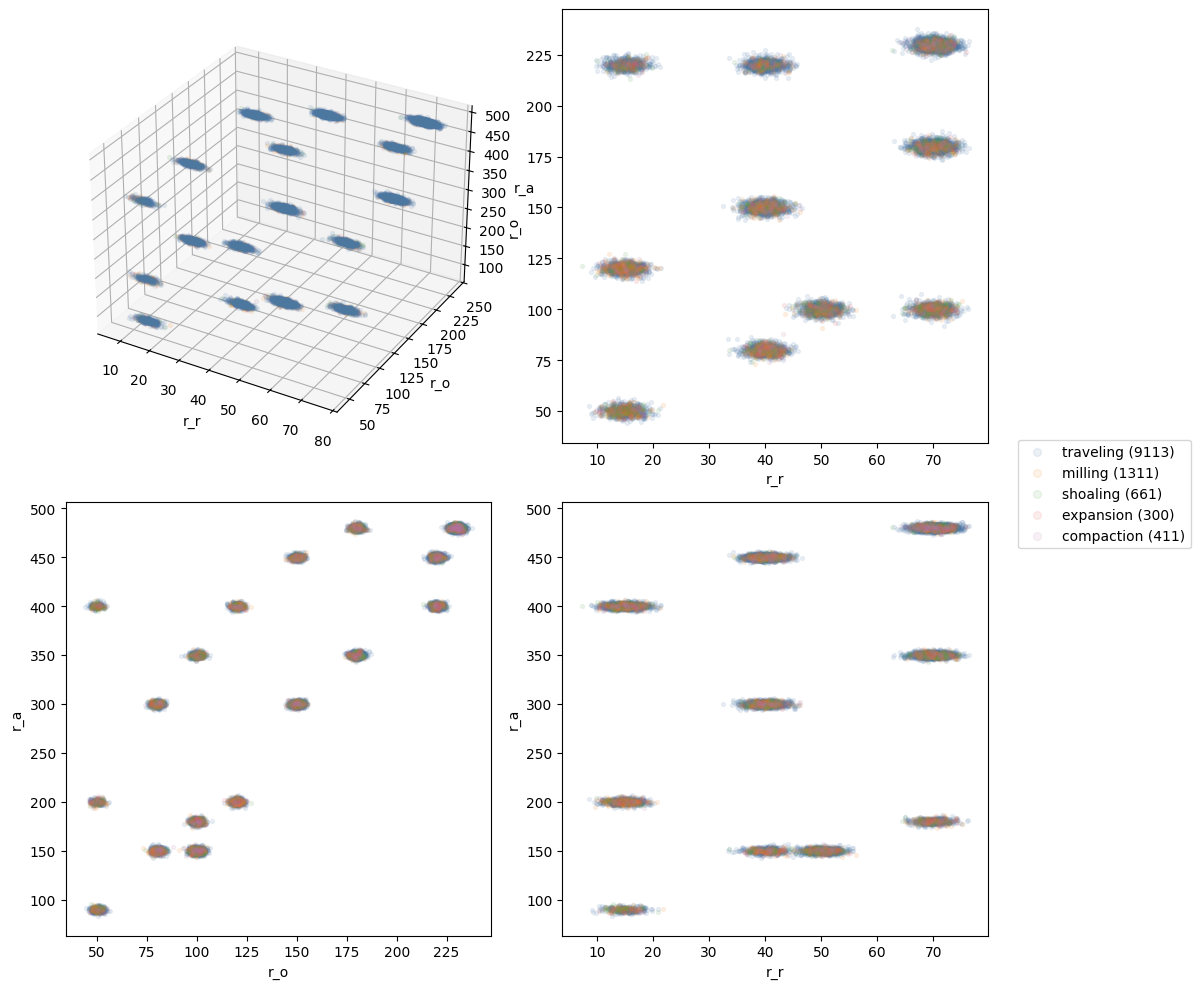

In [13]:
scatter_radii(BEHAVIOR_ORDER, "label", BEHAVIOR_COLORS)


## By school size

The same windows, colored by the dataset's fish group.

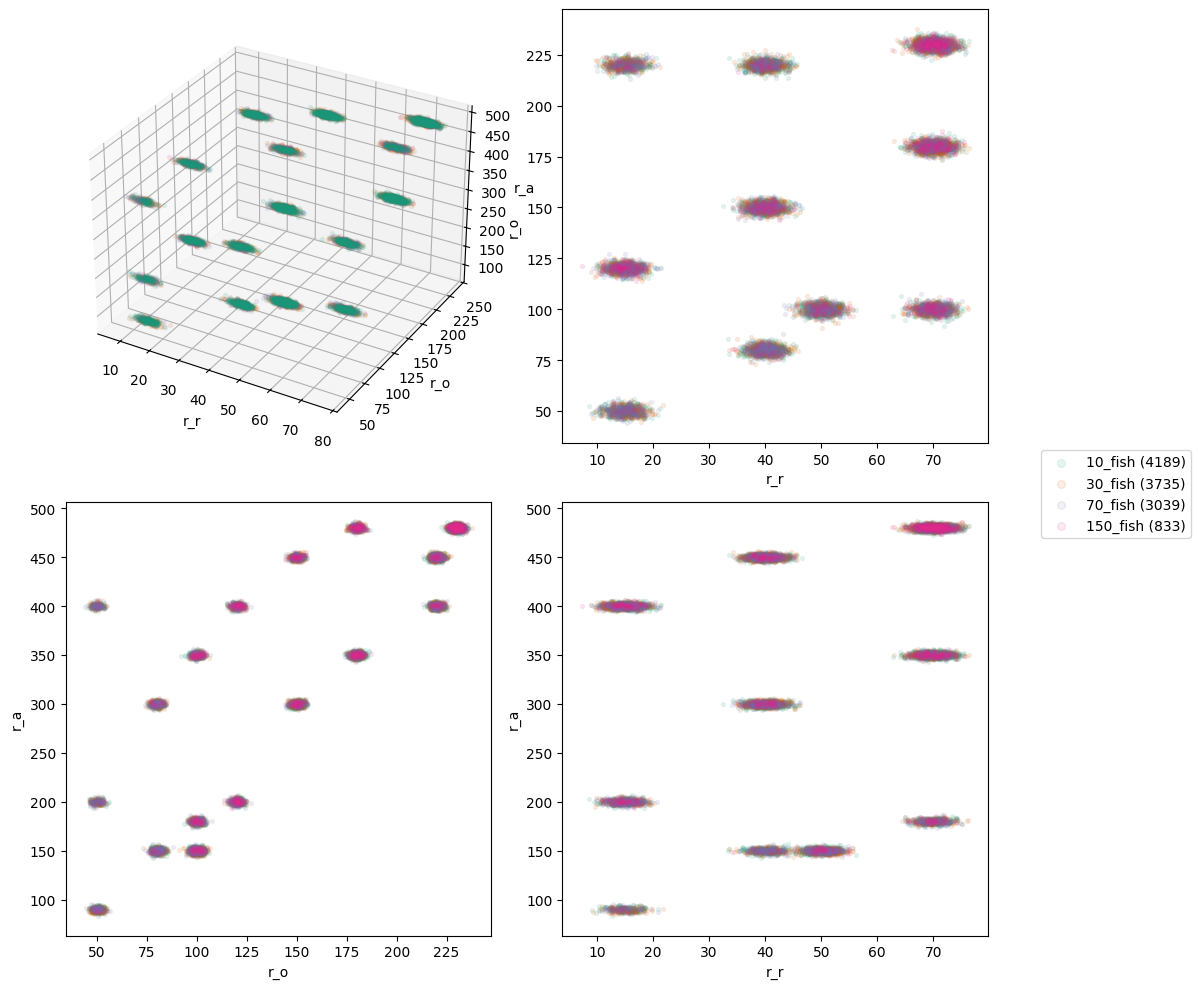

In [14]:
scatter_radii(SIZE_ORDER, "school_size", SIZE_COLORS)
